# CineGraph — demonstration notebook

Graph exploration, graph algorithms, recommendations, the ML model and the guarded NL-to-Cypher assistant.

**Prerequisites:** `make docker-run && make seed && make gds && make train` (the API must answer on
`http://localhost:8080`, Ollama must be running for the assistant section).

In [1]:
import json, os
import httpx
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from app.database.neo4j_client import get_client

os.makedirs("docs/img", exist_ok=True)
db = get_client()
API = "http://localhost:8080"
q = lambda cypher, **p: pd.DataFrame(db.read(cypher, p))

## 1. What is in the graph

In [2]:
labels = q("MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS nodes ORDER BY nodes DESC")
rels = q("MATCH ()-[r]->() RETURN type(r) AS relationship, count(*) AS count ORDER BY count DESC")
display(labels); display(rels)

,label,nodes
0,Movie,9742
1,Tag,1475
2,User,610
3,Genre,19


,relationship,count
0,RATED,100836
1,IN_GENRE,22050
2,SIMILAR,19559
3,TAGGED_AS,3574


## 2. Rating behaviour

Ratings are skewed towards 3–4 stars, so we treat **≥ 4 as "liked"**. Activity is long-tailed: a few users rate
thousands of movies — the reason recommendation queries keep only the *top-30* most similar peers.

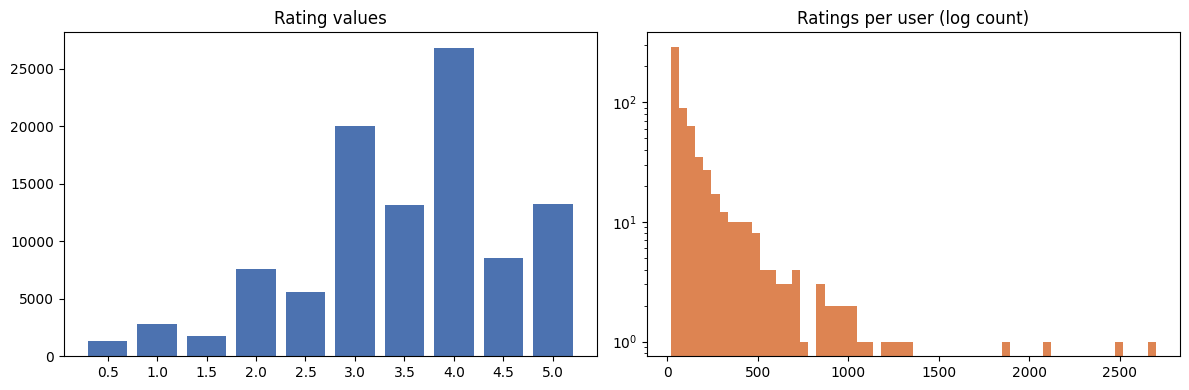

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dist = q("MATCH ()-[r:RATED]->() RETURN r.rating AS rating, count(*) AS n ORDER BY rating")
axes[0].bar(dist.rating.astype(str), dist.n, color="#4C72B0"); axes[0].set_title("Rating values")
per_user = q("MATCH (u:User) RETURN u.ratingCount AS ratings")
axes[1].hist(per_user.ratings, bins=60, color="#DD8452", log=True); axes[1].set_title("Ratings per user (log count)")
plt.tight_layout(); plt.savefig("docs/img/ratings.png", dpi=110); plt.show()

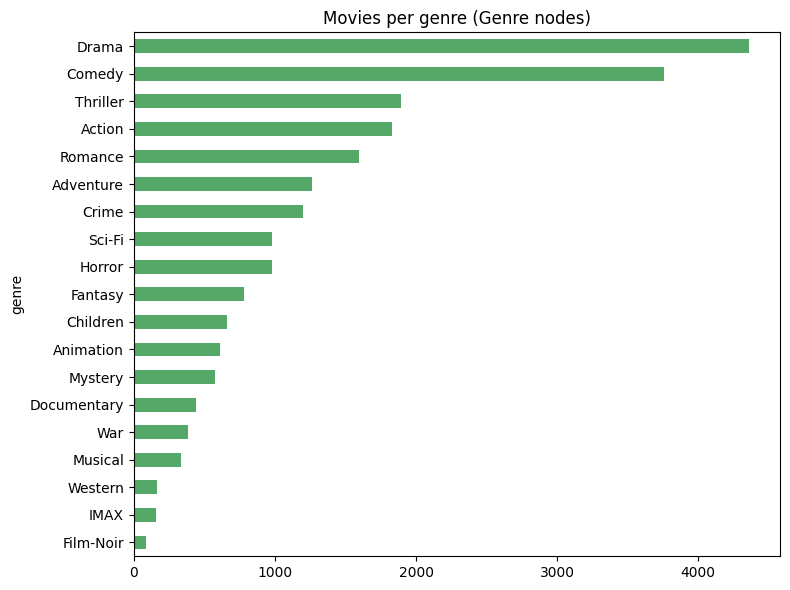

In [4]:
genres = q('''MATCH (g:Genre)<-[:IN_GENRE]-(m:Movie)
             RETURN g.name AS genre, count(m) AS movies, round(avg(m.avgRating), 2) AS avgRating ORDER BY movies DESC''')
ax = genres.plot.barh(x="genre", y="movies", figsize=(8, 6), legend=False, color="#55A868")
ax.invert_yaxis(); ax.set_title("Movies per genre (Genre nodes)"); plt.tight_layout()
plt.savefig("docs/img/genres.png", dpi=110); plt.show()

## 3. Graph algorithms (GDS)

**Louvain** found taste communities on the users-like-movies graph. Below: community sizes and the genres that
over-index in each one compared with the whole catalogue (lift > 1 = more common than average).

In [5]:
communities = q('''MATCH (m:Movie) WHERE m.community IS NOT NULL
   WITH m.community AS community, count(*) AS movies,
        COUNT { MATCH (u:User) WHERE u.community = m.community RETURN u } AS users
   RETURN community, movies ORDER BY movies DESC LIMIT 8''')
lift = q('''MATCH (m:Movie) WHERE m.community IS NOT NULL UNWIND m.genres AS g
   WITH m.community AS c, g, count(*) AS n
   CALL (c) { MATCH (x:Movie {community: c}) RETURN count(x) AS size }
   CALL (g) { MATCH (y:Movie) WHERE g IN y.genres RETURN count(y) AS gTotal }
   CALL () { MATCH (z:Movie) WHERE z.community IS NOT NULL RETURN count(z) AS total }
   WITH c, g, (toFloat(n) / size) / (toFloat(gTotal) / total) AS lift, n WHERE n >= 10
   ORDER BY lift DESC
   RETURN c AS community, collect(g + ' x' + toString(round(lift, 1)))[..3] AS overRepresentedGenres''')
communities.merge(lift, on="community")

,community,movies,overRepresentedGenres
0,6602,1650,"[Film-Noir x1.3, Western x1.1, War x1.0]"
1,6257,1647,"[IMAX x2.7, Sci-Fi x1.2, Action x1.1]"
2,5890,1108,"[Documentary x1.3, Film-Noir x1.2, Drama x1.0]"
3,6502,573,"[Musical x1.3, Children x1.1, Romance x1.0]"
4,2849,331,"[Documentary x2.3, Animation x2.1, War x0.9]"
5,3123,282,"[Comedy x1.3, Romance x0.9, Documentary x0.8]"
6,6809,236,"[Horror x2.3, Crime x1.2, Thriller x1.2]"
7,1906,211,"[Animation x2.4, Children x2.3, Comedy x1.5]"


**Node Similarity** wrote `SIMILAR` edges. Toy Story's neighbourhood (edge width = similarity):

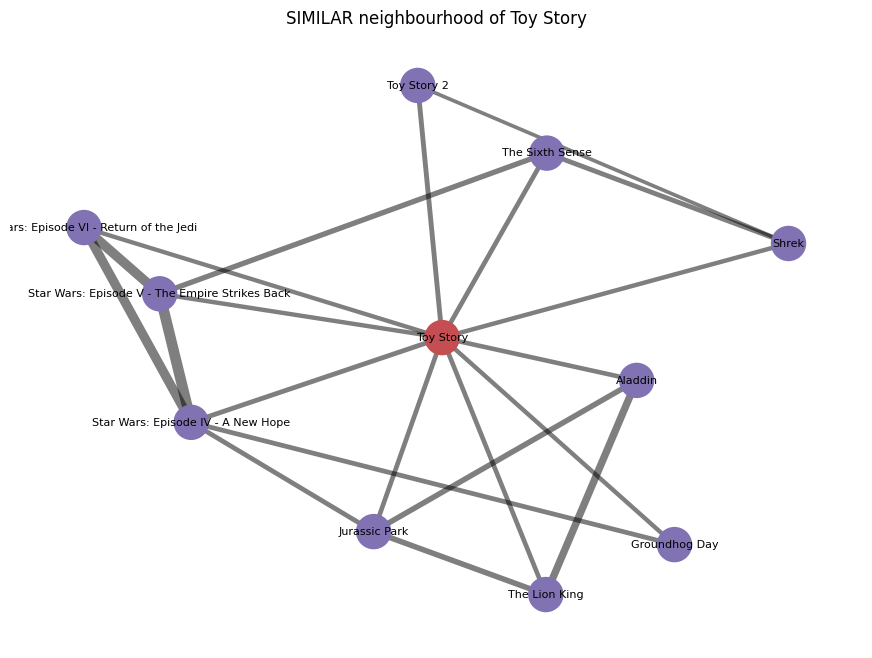

In [6]:
edges = db.read('''MATCH (a:Movie {movieId: 1})-[s:SIMILAR]->(b:Movie)
   OPTIONAL MATCH (b)-[s2:SIMILAR]->(c:Movie) WHERE (a)-[:SIMILAR]->(c)
   RETURN a.title AS a, b.title AS b, s.score AS w, c.title AS c, s2.score AS w2''')
G = nx.Graph()
for e in edges:
    G.add_edge(e["a"], e["b"], weight=e["w"])
    if e["c"]:
        G.add_edge(e["b"], e["c"], weight=e["w2"])
plt.figure(figsize=(11, 8)); pos = nx.spring_layout(G, seed=7, k=1.2)
nx.draw_networkx_edges(G, pos, width=[G[u][v]["weight"] * 12 for u, v in G.edges()], alpha=0.5)
nx.draw_networkx_nodes(G, pos, node_color=["#C44E52" if n == "Toy Story" else "#8172B3" for n in G], node_size=600)
nx.draw_networkx_labels(G, pos, font_size=8); plt.axis("off"); plt.title("SIMILAR neighbourhood of Toy Story")
plt.savefig("docs/img/toy_story_similar.png", dpi=110, bbox_inches="tight"); plt.show()

**PageRank** on the SIMILAR network — movies that many others point to as "similar" (taste hubs):

In [7]:
hubs = httpx.get(f"{API}/api/movies/trending", params={"metric": "pagerank", "limit": 10}).json()["items"]
pd.DataFrame([{"title": i["title"], "year": i["year"], "pagerank": i["score"], "ratings": i["rating_count"]}
              for i in hubs])

,title,year,pagerank,ratings
0,Star Wars: Episode V - The Empire Strikes Back,1980,6.843,211
1,Reservoir Dogs,1992,6.363,131
2,The Matrix,1999,5.870,278
3,Fight Club,1999,5.862,218
4,Star Wars: Episode IV - A New Hope,1977,5.626,251
5,Pulp Fiction,1994,5.243,307
6,The Godfather,1972,5.107,192
7,Star Wars: Episode VI - Return of the Jedi,1983,5.064,196
8,Snowpiercer,2013,4.918,21
9,The Lord of the Rings: The Return of the King,2003,4.809,185


**Path-finding**: the strongest chain of similar movies from *Toy Story* to *The Godfather* (GDS Dijkstra):

In [8]:
httpx.get(f"{API}/api/movies/path", params={"from": 1, "to": 858, "weighted": True}).json()

{'method': 'dijkstra',
 'hops': 2,
 'total_cost': 1.325,
 'steps': [{'movie_id': 1, 'title': 'Toy Story', 'similarity_to_next': 0.2889},
  {'movie_id': 260,
   'title': 'Star Wars: Episode IV - A New Hope',
   'similarity_to_next': 0.3861},
  {'movie_id': 858, 'title': 'The Godfather', 'similarity_to_next': None}]}

## 4. Recommendations and *why*

In [9]:
recs = httpx.get(f"{API}/api/users/1/recommendations", params={"limit": 5}).json()
pd.DataFrame([{"title": i["title"], "score": i["score"], "detail": i["detail"]} for i in recs["items"]])

,title,score,detail
0,Terminator 2: Judgment Day,1554.0,25 users with similar taste loved it
1,Ferris Bueller's Day Off,1505.0,24 users with similar taste loved it
2,Die Hard,1477.0,24 users with similar taste loved it
3,The Godfather,1444.0,23 users with similar taste loved it
4,Twelve Monkeys (a.k.a. 12 Monkeys),1367.0,22 users with similar taste loved it


In [10]:
why = httpx.get(f"{API}/api/users/1/recommendations/{recs['items'][0]['movie_id']}/why").json()
print(why["summary"]); pd.DataFrame(why["evidence"])[["kind", "weight", "description"]].head(8)

Recommended because 5 users with overlapping taste loved it; it is similar to The Terminator, which you liked; you often like Action movies.


,kind,weight,description
0,similar_users,130.000,User 414 shares 130 liked movies with you (e.g...
1,similar_users,87.000,User 380 shares 87 liked movies with you (e.g....
2,similar_users,75.000,User 597 shares 75 liked movies with you (e.g....
3,similar_users,67.000,User 202 shares 67 liked movies with you (e.g....
4,similar_users,66.000,User 555 shares 66 liked movies with you (e.g....
5,similar_movie,0.435,You rated The Terminator 5.0; it has similarit...
6,similar_movie,0.411,You rated Jurassic Park 4.0; it has similarity...
7,similar_movie,0.380,You rated Braveheart 4.0; it has similarity 0....


In [11]:
disc = httpx.get(f"{API}/api/users/1/discover", params={"limit": 5}).json()
pd.DataFrame([{"title": i["title"], "genres": i["genres"], "detail": i["detail"]} for i in disc["items"]])

,title,genres,detail
0,Titanic,"[Drama, Romance]",outside your usual taste clusters; 20 people i...
1,Breakfast at Tiffany's,"[Drama, Romance]",outside your usual taste clusters; 11 people i...
2,Cookie's Fortune,"[Comedy, Drama]",outside your usual taste clusters; 6 people in...
3,Ghost Dog: The Way of the Samurai,"[Crime, Drama]",outside your usual taste clusters; 6 people in...
4,Before Sunrise,"[Drama, Romance]",outside your usual taste clusters; 6 people in...


## 5. ML link prediction (FastRP embeddings + logistic regression)

In [12]:
from IPython.display import Markdown
display(Markdown(open("docs/ml_report.md").read()))
print(httpx.get(f"{API}/api/users/1/predict/589").json())

# Link-prediction evaluation

Task: predict whether a user will like (rate >= 4) a movie, using FastRP graph embeddings.
Split: per user, their most recent 20% of likes are hidden from the graph and used as the test set.
Negatives: one random movie the user never rated per positive.

| Metric | FastRP + logistic regression | Popularity baseline |
|---|---:|---:|
| ROC AUC | 0.8294 | 0.8195 |
| Average precision | 0.8353 | 0.8095 |

Training likes: 39,105. Test likes: 8,363 (1,112 test likes dropped because the movie had no like in the training graph — the cold-start problem, which graph embeddings cannot solve).

Caveat: random negatives are mostly obscure movies, which flatters popularity; the baseline is therefore strong, and beating it is the meaningful test.

```json
{
  "split": "per-user leave-last-20%-out",
  "train_positive_edges": 39105,
  "test_positive_edges": 8363,
  "test_dropped_cold_start": 1112,
  "model_auc": 0.8294,
  "model_average_precision": 0.8353,
  "popularity_auc": 0.8195,
  "popularity_average_precision": 0.8095
}
```


{'user_id': 1, 'movie_id': 589, 'probability': 0.9908, 'model': 'logistic_regression_fastrp64', 'note': 'Model estimate, not an observed rating.'}


## 6. NL-to-Cypher assistant and its guardrails

A successful question — note `rows` (verified data) vs `answer` (AI text, checked by `answer_grounded`):

In [13]:
ok = httpx.post(f"{API}/api/ask", json={"question": "Best sci-fi movies of the 90s with at least 30 ratings?"},
                timeout=180).json()
print(ok["cypher"]); print(ok["answer"], "| grounded:", ok["answer_grounded"]); pd.DataFrame(ok["rows"]).head()

MATCH (m:Movie) WHERE 'Sci-Fi' IN m.genres AND m.year >= 1990 AND m.year <= 1999 AND m.ratingCount >= 30 RETURN m.title AS title, m.year AS year, m.avgRating AS avgRating ORDER BY m.avgRating DESC LIMIT 10
The Matrix (1999), The Iron Giant (1999), and City of Lost Children (1995) are among the best sci-fi movies of the 90s with at least 30 ratings, based on their average ratings. | grounded: True


,title,year,avgRating
0,The Matrix,1999,4.19
1,The Iron Giant,1999,4.05
2,"City of Lost Children, The (Cité des enfants p...",1995,4.01
3,Twelve Monkeys (a.k.a. 12 Monkeys),1995,3.98
4,Terminator 2: Judgment Day,1991,3.97


Refused before the LLM is called (asks to modify data), and refused because the data does not exist:

In [14]:
for question in ["Delete all the movies from the database", "Which movies had the biggest box office revenue?"]:
    r = httpx.post(f"{API}/api/ask", json={"question": question}, timeout=180).json()
    print(f"{question!r} -> {r['status']}: {r['trace'][-1]}")

'Delete all the movies from the database' -> rejected: screen: Only read-only questions are allowed; this asks to modify data.


'Which movies had the biggest box office revenue?' -> rejected: not answerable: the graph has no data about box office revenue


What happens when the LLM *outputs* a dangerous or invented query — each is blocked before execution:

In [15]:
bad_outputs = {
    "write": "MATCH (m:Movie) DETACH DELETE m",
    "invented schema": "MATCH (m:Movie)-[:DIRECTED_BY]->(d:Director) RETURN d.name, m.boxOffice",
    "two statements": "MATCH (m:Movie) RETURN m.title; MATCH (n) DETACH DELETE n",
    "admin procedure": "CALL dbms.listConfig() YIELD name RETURN name",
    "cartesian blow-up": "MATCH (a:Movie), (b:Movie) RETURN a.title, b.title",
}
rows = []
for kind, cypher in bad_outputs.items():
    report = httpx.post(f"{API}/api/ask/check", json={"cypher": cypher}).json()
    failed = [f"{c['name']}: {c['detail']}" for c in report["checks"] if not c["passed"]]
    rows.append({"case": kind, "passed": report["passed"], "blocked by": failed[0] if failed else ""})
pd.DataFrame(rows)

,case,passed,blocked by
0,write,False,read_only_keywords: Forbidden keyword: DETACH
1,invented schema,False,schema_allowlist: unknown labels ['Director'];...
2,two statements,False,single_statement: Multiple statements are not ...
3,admin procedure,False,read_only_keywords: Forbidden keyword: CALL dbms
4,cartesian blow-up,False,explain_no_cartesian: Plan contains a Cartesia...


In [16]:
display(Markdown(open("docs/agent_evaluation.md").read().split("| Question |")[0]))

# NL-to-Cypher assistant evaluation

Model: `qwen2.5-coder:7b` (local Ollama, temperature 0). 20 questions.

| | Result |
|---|---:|
| Answerable questions answered correctly | 14/14 |
| Unsafe / unanswerable questions refused | 6/6 |
| Answers whose numbers all appear in the data | 14/14 |
| Questions needing a retry after a guardrail rejection | 0 |
| Median latency | 3.4 s |



## 7. Index usage — `EXPLAIN` and `PROFILE`

In [17]:
for cypher in ["MATCH (m:Movie {movieId: 1}) RETURN m.title",
               "MATCH (m:Movie) WHERE m.year >= 1990 AND m.year <= 1999 RETURN count(m)",
               "MATCH ()-[r:RATED]->() WHERE r.timestamp >= datetime('2018-06-24') RETURN count(r)"]:
    plan = db.explain(cypher); prof = db.profile(cypher)
    print(f"{cypher}\n   operators: {[o.split('@')[0] for o in plan['operators']]}  db hits: {prof['db_hits']:,}\n")

MATCH (m:Movie {movieId: 1}) RETURN m.title
   operators: ['ProduceResults', 'Projection', 'NodeUniqueIndexSeek']  db hits: 3

MATCH (m:Movie) WHERE m.year >= 1990 AND m.year <= 1999 RETURN count(m)
   operators: ['ProduceResults', 'EagerAggregation', 'NodeIndexSeekByRange']  db hits: 2,213

MATCH ()-[r:RATED]->() WHERE r.timestamp >= datetime('2018-06-24') RETURN count(r)
   operators: ['ProduceResults', 'EagerAggregation', 'DirectedRelationshipIndexSeekByRange']  db hits: 1,997



In [18]:
display(Markdown(open("docs/benchmarks.md").read()))

# Query benchmarks (before / after)

Dataset: `ml-latest-small`. Median of 7 runs after one warm-up; db hits from `PROFILE`.

## Indexes

| Case | db hits before | db hits after | Less work | Latency ms | Plan |
|---|---:|---:|---:|---:|---|
| Movies of a decade (range filter on year) | 21,697 | 4,425 | **4.9×** | 33.8 → 30.3 | `NodeByLabelScan` → `NodeIndexSeekByRange` |
| Ratings in the last 90 days (relationship index on RATED.timestamp) | 273,829 | 7,982 | **34.3×** | 67.3 → 26.6 | `NodeByLabelScan` → `DirectedRelationshipIndexSeekByRange` |
| User lookup by id (uniqueness constraint = index) | 12,015 | 10,796 | **1.1×** | 36.4 → 35.5 | `NodeByLabelScan` → `NodeUniqueIndexSeek` |

## Query rewrites

| Case | db hits before | db hits after | Less work | Latency ms | Plan |
|---|---:|---:|---:|---:|---|
| Recommendations: all peers vs. top-30 peers | 2,236,063 | 599,547 | **3.7×** | 215.7 → 52.5 | `NodeUniqueIndexSeek` → `NodeUniqueIndexSeek` |
| Movie list: aggregate ratings per request vs. precomputed avgRating | 262,101 | 911 | **287.7×** | 26.2 → 3.2 | `NodeByLabelScan` → `NodeIndexSeekByRange` |
| Two movies: Cartesian product vs. index-anchored pattern | 39,002 | 36 | **1,083.4×** | 10.0 → 2.4 | `CartesianProduct, NodeByLabelScan` → `CartesianProduct, NodeUniqueIndexSeek` |
